# ЛР1, завдання 4 — первинний огляд даних
Кейс 9: будівельна техніка та самоскиди на майданчику.

**Дані:** у цій версії використано **синтетичну сцену** — ортофотоплан будмайданчика,
згенерований скриптом `synth_site.py` (GSD 0,05 м, EPSG:32635). Для реальної сцени
OpenAerialMap достатньо покласти її поруч під назвою `scene.tif` — комірка генерації її не перезапише.

In [1]:
!pip -q install rasterio pyproj

In [2]:
import numpy as np, rasterio, matplotlib.pyplot as plt
from rasterio.warp import calculate_default_transform, reproject, Resampling

PATH = "scene.tif"
import os, json, sys
sys.path.append("../common"); sys.path.append(".")
if not os.path.exists(PATH):                      # генерація синтетичної сцени
    from synth_site import make_site, CLASSES
    from rasterio.transform import from_origin
    img, objs = make_site(2400, 2400, gsd=0.05, seed=11, n_machines=12, style={"axis": True})
    with rasterio.open(PATH, "w", driver="GTiff", height=img.shape[0], width=img.shape[1], count=3,
                       dtype="uint8", crs="EPSG:32635", transform=from_origin(286000, 5476000, 0.05, 0.05)) as d:
        d.write(img.transpose(2, 0, 1)); d.update_tags(ACQUISITION_DATE="2026-10-20 (синтетична)")
    json.dump([(CLASSES[c], x0, y0, x1, y1) for c, x0, y0, x1, y1 in objs], open("scene_objects.json", "w"))

with rasterio.open(PATH) as src:
    print("CRS:", src.crs)
    print("Розмір, пкс (W x H):", src.width, "x", src.height)
    print("Кількість каналів:", src.count, "| тип:", src.dtypes[0])
    print("Розмір пікселя (од. CRS):", src.res)
    print("Межі сцени:", src.bounds)
    print("Теги (шукай дату знімання):", src.tags())

CRS: EPSG:32635
Розмір, пкс (W x H): 2400 x 2400
Кількість каналів: 3 | тип: uint8
Розмір пікселя (од. CRS): (0.05, 0.05)
Межі сцени: BoundingBox(left=286000.0, bottom=5475880.0, right=286120.0, top=5476000.0)
Теги (шукай дату знімання): {'ACQUISITION_DATE': '2026-10-20 (синтетична)', 'AREA_OR_POINT': 'Area'}


Якщо CRS географічна (EPSG:4326, градуси) або EPSG:3857 (метри Меркатора, спотворені на широті України),
перепроєктуємо у UTM, щоб отримати чесний розмір пікселя в метрах.

In [3]:
def to_utm(path, out="scene_utm.tif"):
    with rasterio.open(path) as src:
        lon = (src.bounds.left + src.bounds.right) / 2
        if src.crs.is_projected and src.crs.to_epsg() != 3857:
            return path
        if src.crs.to_epsg() == 3857:
            from pyproj import Transformer
            lon, _ = Transformer.from_crs(3857, 4326, always_xy=True).transform(
                (src.bounds.left + src.bounds.right) / 2, (src.bounds.bottom + src.bounds.top) / 2)
        zone = int((lon + 180) // 6) + 1
        dst_crs = f"EPSG:{32600 + zone}"
        tr, w, h = calculate_default_transform(src.crs, dst_crs, src.width, src.height, *src.bounds)
        meta = src.meta.copy(); meta.update(crs=dst_crs, transform=tr, width=w, height=h)
        with rasterio.open(out, "w", **meta) as dst:
            for b in range(1, src.count + 1):
                reproject(rasterio.band(src, b), rasterio.band(dst, b),
                          src_transform=src.transform, src_crs=src.crs,
                          dst_transform=tr, dst_crs=dst_crs, resampling=Resampling.bilinear)
    return out

PATH_M = to_utm(PATH)
with rasterio.open(PATH_M) as src:
    gsd = src.res[0]
    rgb = src.read([1, 2, 3]).astype(float)
    print("CRS:", src.crs, "| GSD = %.3f м" % gsd)
    print("Розмір сцени на місцевості: %.0f x %.0f м" % (src.width * gsd, src.height * gsd))

CRS: EPSG:32635 | GSD = 0.050 м
Розмір сцени на місцевості: 120 x 120 м


## Вимоги з завдання 2 → скільки пікселів займе об'єкт
Мінімальні сторони об'єктів (м) з таблиці класів звіту.

In [4]:
objects = {"самоскид": 2.5, "екскаватор": 3.0, "кран (автокран)": 2.6,
           "інша техніка/авто": 1.8}
N_PX_DET = 15   # n_px для детектування і розрізнення класів (формула 1.6, звіт розд. 3)
for name, s in objects.items():
    print(f"{name:20s}: {s / gsd:6.1f} пкс уздовж меншої сторони;"
          f" потрібний GSD <= {s / N_PX_DET:.2f} м")

самоскид            :   50.0 пкс уздовж меншої сторони; потрібний GSD <= 0.17 м
екскаватор          :   60.0 пкс уздовж меншої сторони; потрібний GSD <= 0.20 м
кран (автокран)     :   52.0 пкс уздовж меншої сторони; потрібний GSD <= 0.17 м
інша техніка/авто   :   36.0 пкс уздовж меншої сторони; потрібний GSD <= 0.12 м


## Виміряні об'єкти
Для синтетичної сцени менша сторона машин вимірюється за еталонними рамками генератора
(для реальної сцени — інструментом «Виміряти лінію» в QGIS).

In [5]:
objs = json.load(open("scene_objects.json"))
measured_m, seen = {}, {}
for name, x0, y0, x1, y1 in objs:
    seen[name] = seen.get(name, 0) + 1
    if seen[name] <= 2: measured_m[f"{name}_{seen[name]}"] = min(x1 - x0, y1 - y0) * gsd
for k, v in measured_m.items():
    flag = "OK" if v / gsd >= N_PX_DET else "мало пікселів"
    print(f"{k:15s} {v:.2f} м -> {v / gsd:.1f} пкс  [{flag}]")

dump_truck_1    2.43 м -> 48.5 пкс  [OK]
excavator_1     8.70 м -> 174.1 пкс  [OK]
dump_truck_2    2.51 м -> 50.3 пкс  [OK]
other_vehicle_1 1.80 м -> 36.0 пкс  [OK]
excavator_2     8.73 м -> 174.6 пкс  [OK]
other_vehicle_2 1.80 м -> 36.0 пкс  [OK]


## Візуалізація та гістограми каналів

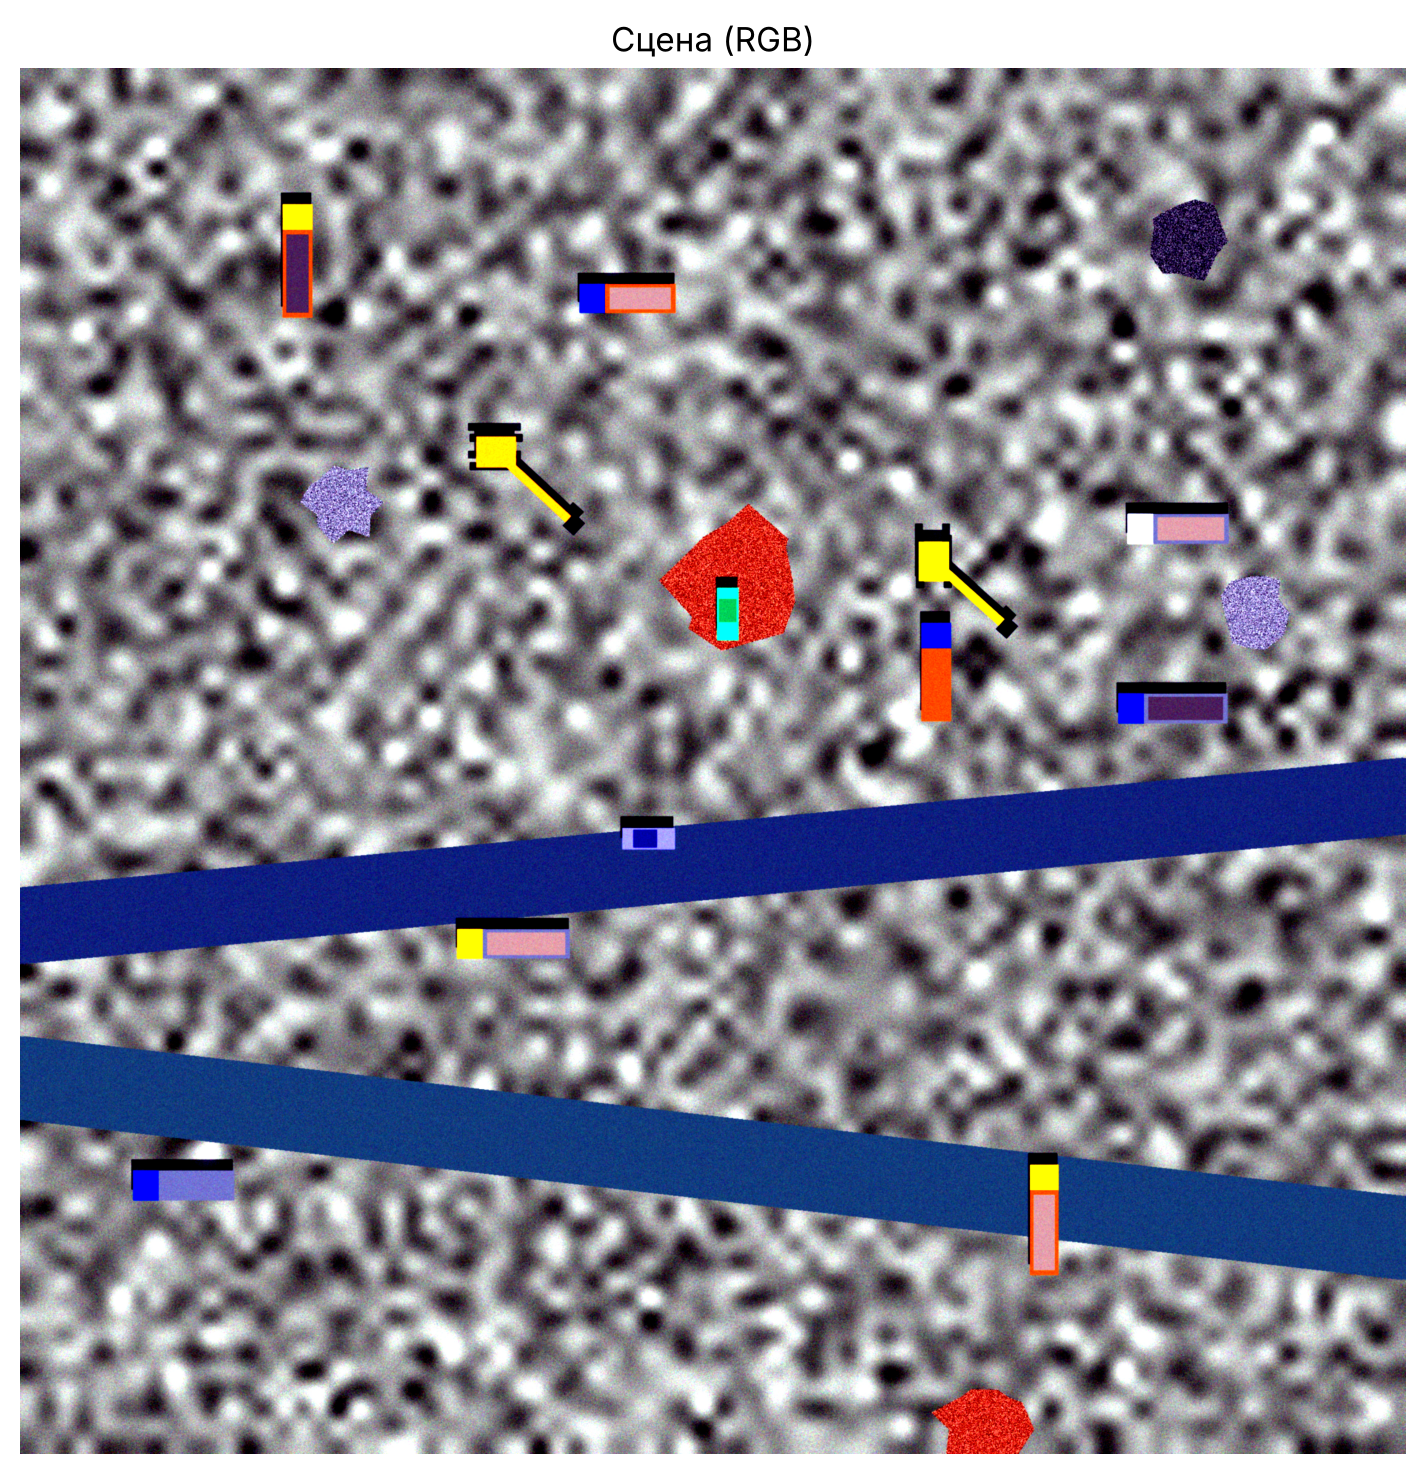

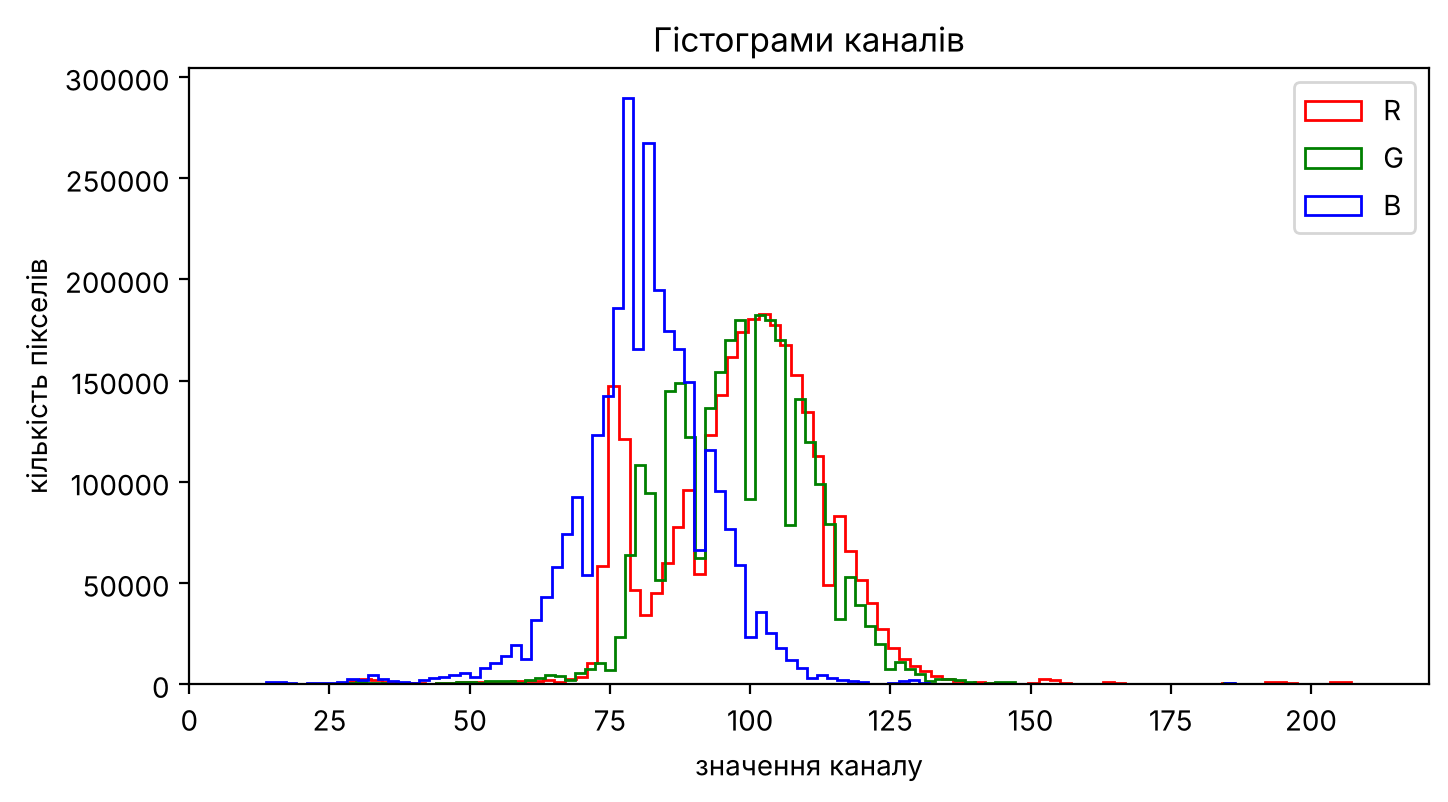

In [6]:
def stretch(a):
    lo, hi = np.percentile(a[a > 0], (2, 98)) if (a > 0).any() else (0, 1)
    return np.clip((a - lo) / (hi - lo + 1e-9), 0, 1)

img = np.dstack([stretch(b) for b in rgb])
step = max(1, max(img.shape[:2]) // 2000)   # прорідження для швидкого показу
plt.figure(figsize=(9, 9)); plt.imshow(img[::step, ::step]); plt.axis("off")
plt.title("Сцена (RGB)"); plt.savefig("fig_scene.png", dpi=150, bbox_inches="tight"); plt.show()

plt.figure(figsize=(8, 4))
for band, c, n in zip(rgb, "rgb", ["R", "G", "B"]):
    v = band[band > 0].ravel()
    plt.hist(v[:: max(1, v.size // 2_000_000)], bins=100, histtype="step", color=c, label=n)
plt.xlabel("значення каналу"); plt.ylabel("кількість пікселів"); plt.legend()
plt.title("Гістограми каналів"); plt.savefig("fig_hist.png", dpi=150, bbox_inches="tight"); plt.show()

## Скільки зразків реально зібрати
Порахуй техніку на сцені вручну (або оцінкою за фрагментом) і впиши.

In [7]:
from collections import Counter
counts_in_scene = Counter(o[0] for o in objs)
n_scenes_available = 6       # стільки сцен генерується для набору ЛР2
for k, v in counts_in_scene.items():
    print(f"{k:20s}: {v} у сцені -> ~{v * n_scenes_available} з {n_scenes_available} сцен")

dump_truck          : 8 у сцені -> ~48 з 6 сцен
excavator           : 2 у сцені -> ~12 з 6 сцен
other_vehicle       : 2 у сцені -> ~12 з 6 сцен
